# Task 1:

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the included Balls image, convert it to a binary image, and remove its frame.
image = cv2.imread("Balls.png", cv2.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError("Balls.png could not be loaded.")

image = image[20:-20, 20:-20]
_, binary = cv2.threshold(
    image, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Use white as the foreground for the morphological operations.
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))

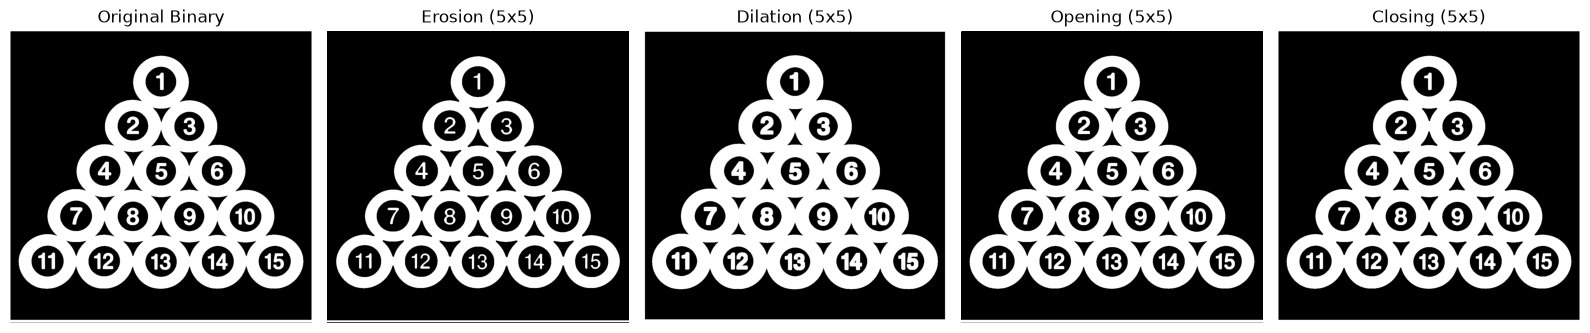

In [2]:
# Apply erosion, dilation, opening, and closing
eroded = cv2.erode(binary, kernel, iterations=1)
dilated = cv2.dilate(binary, kernel, iterations=1)
opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

images = [binary, eroded, dilated, opened, closed]
titles = ["Original Binary", "Erosion (5x5)", "Dilation (5x5)",
          "Opening (5x5)", "Closing (5x5)"]

fig, ax = plt.subplots(1, 5, figsize=(16, 4))
for axis, result, title in zip(ax, images, titles):
    axis.imshow(result, cmap="gray", vmin=0, vmax=255)
    axis.set_title(title)
    axis.axis("off")

plt.tight_layout()
plt.show()

# Task 2:

In [3]:
# Compare square, cross, and ellipse structuring elements at three sizes
shapes = {
    "Square": cv2.MORPH_RECT,
    "Cross": cv2.MORPH_CROSS,
    "Ellipse": cv2.MORPH_ELLIPSE,
}
sizes = [3, 5, 7]

eroded_results = {}
dilated_results = {}

for shape_name, shape in shapes.items():
    for size in sizes:
        structuring_element = cv2.getStructuringElement(shape, (size, size))
        eroded_results[(shape_name, size)] = cv2.erode(binary, structuring_element)
        dilated_results[(shape_name, size)] = cv2.dilate(binary, structuring_element)


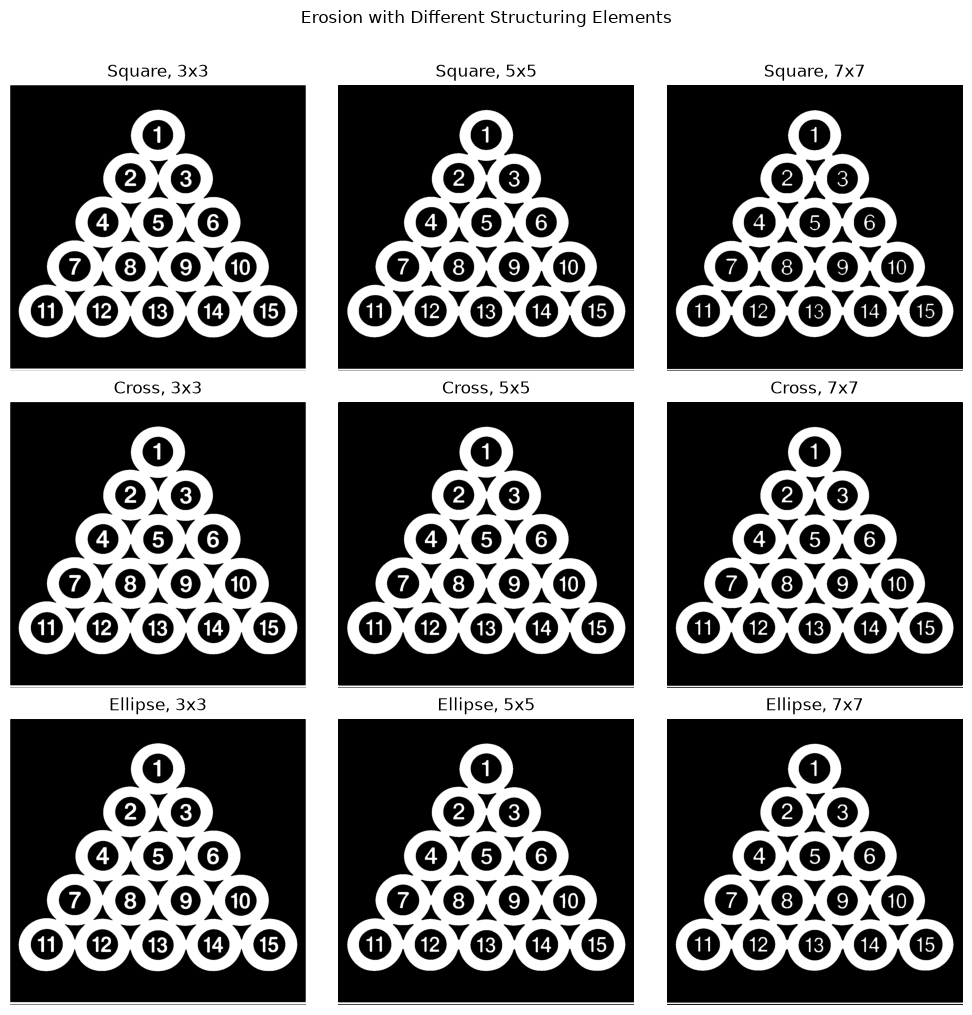

In [4]:
# Display erosion results: rows are shapes and columns are kernel sizes
fig, ax = plt.subplots(3, 3, figsize=(10, 10))

for row, shape_name in enumerate(shapes):
    for column, size in enumerate(sizes):
        result = eroded_results[(shape_name, size)]
        ax[row, column].imshow(result, cmap="gray", vmin=0, vmax=255)
        ax[row, column].set_title(f"{shape_name}, {size}x{size}")
        ax[row, column].axis("off")

plt.suptitle("Erosion with Different Structuring Elements", y=1.01)
plt.tight_layout()
plt.show()

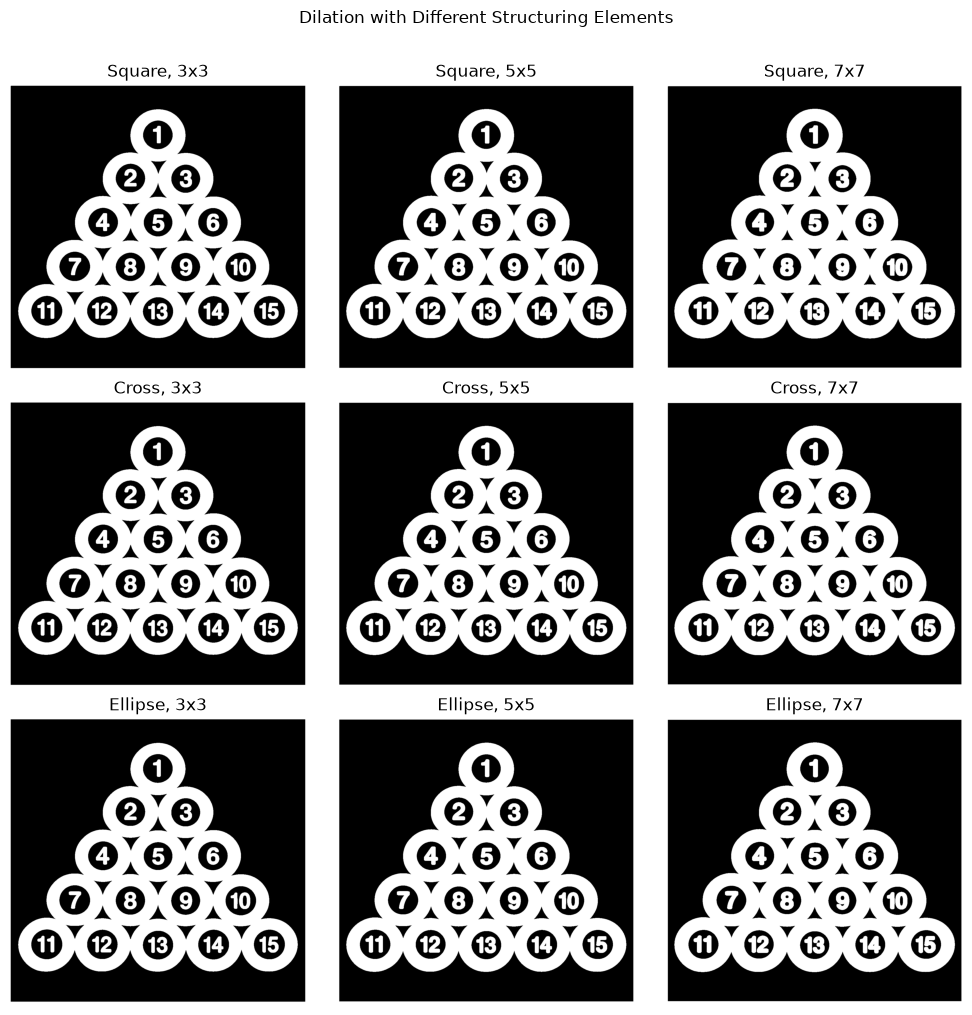

In [5]:
# Display dilation results: rows are shapes and columns are kernel sizes
fig, ax = plt.subplots(3, 3, figsize=(10, 10))

for row, shape_name in enumerate(shapes):
    for column, size in enumerate(sizes):
        result = dilated_results[(shape_name, size)]
        ax[row, column].imshow(result, cmap="gray", vmin=0, vmax=255)
        ax[row, column].set_title(f"{shape_name}, {size}x{size}")
        ax[row, column].axis("off")

plt.suptitle("Dilation with Different Structuring Elements", y=1.01)
plt.tight_layout()
plt.show()


In [6]:
# Count foreground pixels to compare how the kernel changes each result
print("Foreground pixel counts for erosion:")
for shape_name in shapes:
    counts = [np.count_nonzero(eroded_results[(shape_name, size)]) for size in sizes]
    print(f"{shape_name}: {dict(zip(sizes, counts))}")

print("\nForeground pixel counts for dilation:")
for shape_name in shapes:
    counts = [np.count_nonzero(dilated_results[(shape_name, size)]) for size in sizes]
    print(f"{shape_name}: {dict(zip(sizes, counts))}")

Foreground pixel counts for erosion:
Square: {3: np.int64(433671), 5: np.int64(403237), 7: np.int64(376292)}
Cross: {3: np.int64(440384), 5: np.int64(416879), 7: np.int64(397042)}
Ellipse: {3: np.int64(440384), 5: np.int64(411735), 7: np.int64(391539)}

Foreground pixel counts for dilation:
Square: {3: np.int64(494010), 5: np.int64(522116), 7: np.int64(549552)}
Cross: {3: np.int64(487480), 5: np.int64(509386), 7: np.int64(530905)}
Ellipse: {3: np.int64(487480), 5: np.int64(514212), 7: np.int64(535764)}


**Comparison:** Increasing the kernel size makes erosion remove more foreground pixels and dilation add more. The square kernel affects diagonal neighbors as well as horizontal and vertical ones; the cross mainly follows horizontal and vertical directions; the ellipse gives a rounder result. The shape and size therefore change the outlines and the narrow gaps between nearby objects.